# 02 · Canonical skeleton & sagittal projection QC

Checks that each loader's joint centres are anatomically sane and that the sagittal projection
(global plane: progression axis × gravity) produces comparable stick figures across datasets.

* **Fukuchi** – Harrington hip regression from ASIS/PSIS; lateral epicondyle/malleolus; heel marker; MT1–MT5 mid as toe.
* **Ferber** – static joint centres (dataset's own definitions) carried into walking by per-frame Kabsch fit of each segment cluster; toe marker; heel = posterior foot-cluster point at floor height.
* **Toronto** – Xsens segment origins; virtual heel rigidly attached to the foot.

*This project is a prototype and is not medical advice.*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis import *
from canonical import J, JOINTS, SIDES
style()
pd.set_option("display.width", 200, "display.max_columns", 40)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


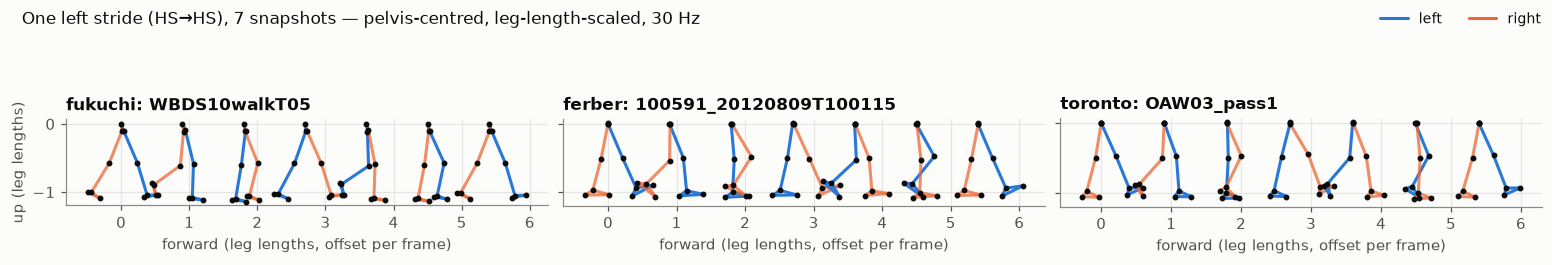

In [2]:
examples = {"fukuchi": "WBDS10walkT05", "ferber": trials("ferber", True).trial.iloc[5], "toronto": "OAW03_pass1"}
fig, axs = plt.subplots(1, 3, figsize=(14, 2.6), sharey=True, layout="constrained")
bones = [("pelvis", "{s}_hip"), ("{s}_hip", "{s}_knee"), ("{s}_knee", "{s}_ankle"),
         ("{s}_ankle", "{s}_heel"), ("{s}_heel", "{s}_toe"), ("{s}_ankle", "{s}_toe")]
for ax, (ds, tr) in zip(axs, examples.items()):
    z = load_npz(ds, tr); sag = z["sag30"]
    hs = z["ev30_HS_L"]; frames = np.linspace(hs[2], hs[3], 7).astype(int)
    for k, f in enumerate(frames):
        off = k * 0.9
        for s in SIDES:
            for a, b in bones:
                a_, b_ = J[a.format(s=s)], J[b.format(s=s)]
                ax.plot(sag[f, [a_, b_], 0] + off, sag[f, [a_, b_], 1], color=SIDE_COL[s], lw=2,
                        alpha=1 if s == "L" else 0.75)
        ax.scatter(sag[f, :, 0] + off, sag[f, :, 1], s=8, color=INK, zorder=3)
    ax.set_title(f"{ds}: {tr}"); ax.set_aspect("equal"); ax.set_xlabel("forward (leg lengths, offset per frame)")
axs[0].set_ylabel("up (leg lengths)")
axs[0].plot([], [], color=SIDE_COL["L"], label="left"); axs[0].plot([], [], color=SIDE_COL["R"], label="right")
fig.legend(loc="upper right", ncol=2, fontsize=9)
fig.suptitle("One left stride (HS→HS), 7 snapshots — pelvis-centred, leg-length-scaled, 30 Hz", x=0.01, ha="left", fontsize=11)
save(fig, "02_stick_figures"); plt.show()

## Keypoint trajectories in the normalised frame
What the model sees: pelvis-centred, leg-length-scaled 2D coordinates resampled to 30 Hz.

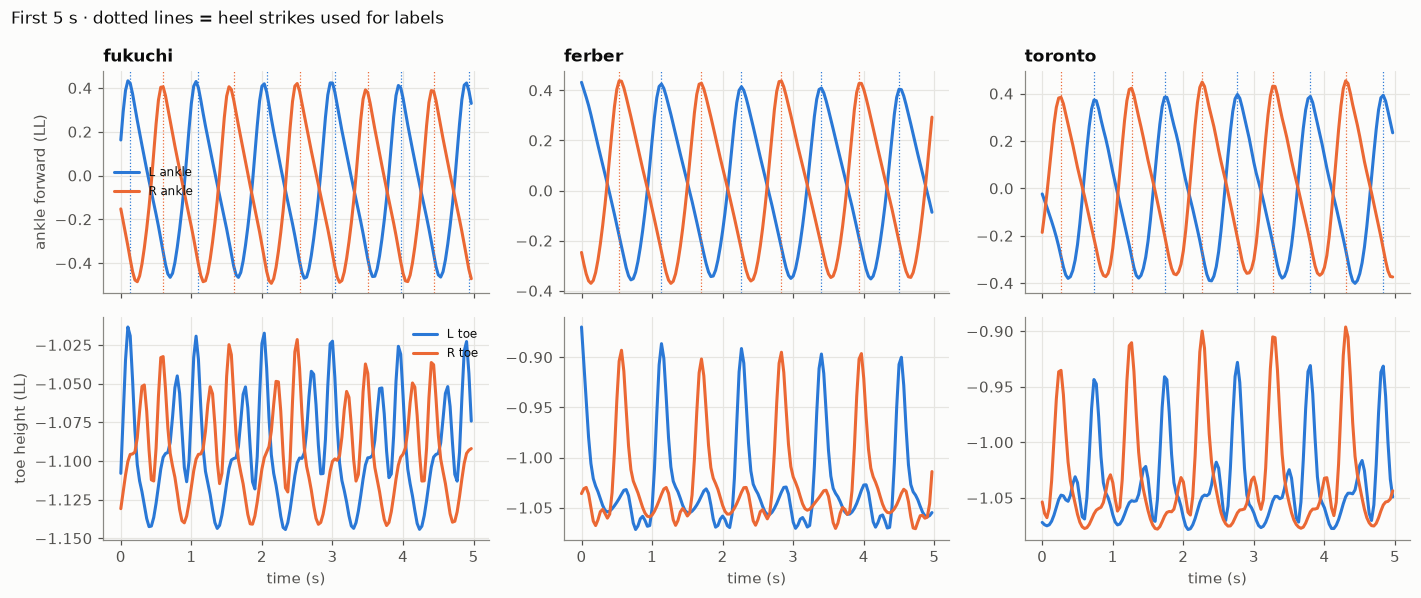

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for c, (ds, tr) in enumerate(examples.items()):
    z = load_npz(ds, tr); sag = z["sag30"]; t = np.arange(len(sag)) / 30
    m = t < 5
    for s in SIDES:
        axs[0, c].plot(t[m], sag[m, J[f"{s}_ankle"], 0], color=SIDE_COL[s], label=f"{s} ankle")
        axs[1, c].plot(t[m], sag[m, J[f"{s}_toe"], 1], color=SIDE_COL[s], label=f"{s} toe")
        for h in z[f"ev30_HS_{s}"]:
            if h / 30 < 5: axs[0, c].axvline(h / 30, color=SIDE_COL[s], lw=0.8, ls=":")
    axs[0, c].set_title(ds); axs[1, c].set_xlabel("time (s)")
axs[0, 0].set_ylabel("ankle forward (LL)"); axs[1, 0].set_ylabel("toe height (LL)")
axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
fig.suptitle("First 5 s · dotted lines = heel strikes used for labels", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "02_trajectories"); plt.show()

## Leg length (hip→ankle in sagittal plane) vs measured height
A wrong joint-centre mapping shows up as a broken height relationship or a dataset offset.

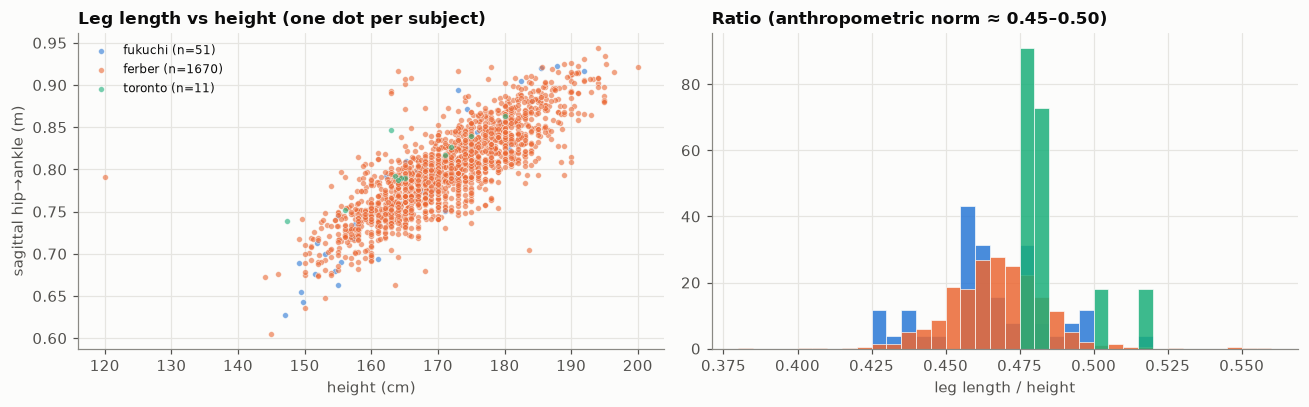

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
ferber,1663.0,0.467,0.017,0.384,0.458,0.467,0.477,0.659
fukuchi,51.0,0.466,0.019,0.427,0.457,0.464,0.478,0.517
toronto,11.0,0.486,0.013,0.478,0.480,0.480,0.483,0.519


In [4]:
K = all_trials()
S = K.groupby(["dataset", "subject"]).agg(leg=("leg_length_sag", "median"), h=("height_cm", "first")).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for d in DATASETS:
    g = S[S.dataset == d]
    axs[0].scatter(g.h, g.leg, s=14, color=COL[d], alpha=0.6, label=f"{d} (n={len(g)})", edgecolor=SURFACE, linewidth=0.4)
    r = (g.leg / (g.h / 100)).dropna()
    axs[1].hist(r, bins=np.arange(0.38, 0.56, 0.005), color=COL[d], alpha=0.85, density=True, label=d, edgecolor=SURFACE, linewidth=0.5)
axs[0].set_xlabel("height (cm)"); axs[0].set_ylabel("sagittal hip→ankle (m)"); axs[0].legend(fontsize=8)
axs[0].set_title("Leg length vs height (one dot per subject)")
axs[1].set_xlabel("leg length / height"); axs[1].set_title("Ratio (anthropometric norm ≈ 0.45–0.50)")
fig.tight_layout(); save(fig, "02_leg_length"); plt.show()
S.assign(ratio=S.leg / (S.h / 100)).groupby("dataset").ratio.describe().round(3)

## Ferber: rigid-cluster reconstruction quality
Median per-frame RMS residual of the Kabsch fit (worst segment per session). Sub-millimetre =
clusters stayed rigid; the 5 mm reject threshold catches marker swaps / cluster slippage.

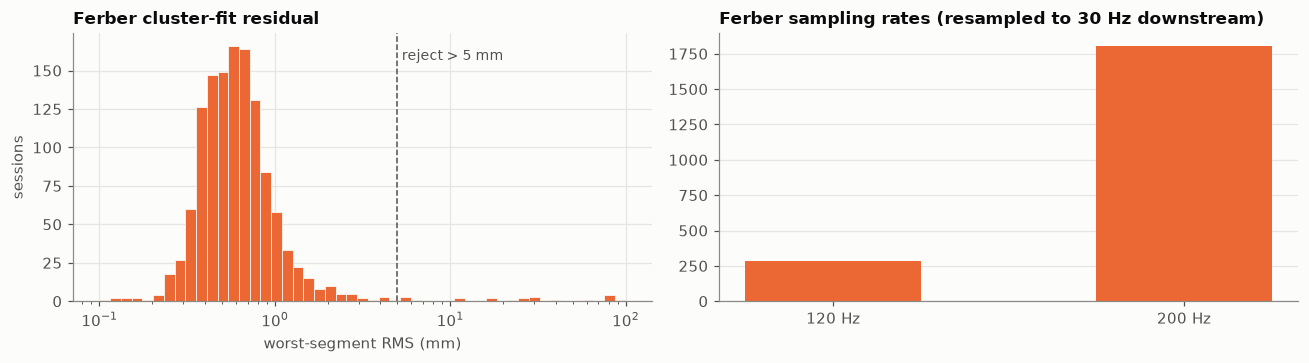

toe_source
marker     1261
virtual     827
Name: count, dtype: int64

In [5]:
R = trials("ferber")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
axs[0].hist(R.max_cluster_rms_mm.dropna(), bins=np.logspace(-1, 2, 50), color=SERIES[1], edgecolor=SURFACE, linewidth=0.5)
axs[0].set_xscale("log"); axs[0].axvline(5, color=INK2, ls="--", lw=1); axs[0].text(5.3, axs[0].get_ylim()[1] * 0.9, "reject > 5 mm", color=INK2, fontsize=9)
axs[0].set_xlabel("worst-segment RMS (mm)"); axs[0].set_ylabel("sessions"); axs[0].set_title("Ferber cluster-fit residual")
fs = R.fs.value_counts().sort_index()
axs[1].bar([f"{int(f)} Hz" for f in fs.index], fs.values, color=SERIES[1], width=0.5)
axs[1].set_title("Ferber sampling rates (resampled to 30 Hz downstream)"); axs[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "02_ferber_qc"); plt.show()
R.toe_source.value_counts(dropna=False)

### Virtual foot (Ferber sessions with no foot landmarks)
Heel = most posterior foot-cluster marker at floor height; toe = static ankle centre + 0.122 × height
straight ahead (subjects stood feet-forward on a template). Both ride on the foot cluster.
Validated by stripping the toe/metatarsal markers from 25 sessions that have them and re-running
the pipeline:

| label | MAE virtual vs real | r |
|---|---|---|
| cadence | 0.00 steps/min | 1.000 |
| stance % | 0.13 % | 0.997 |
| step-time SI | 0.04 % | 1.000 |
| knee ROM | 0.00° | 1.000 |
| ankle ROM | 1.2° (−1.0° bias) | 0.980 |

Only the ankle angle (which uses the toe) is materially affected.

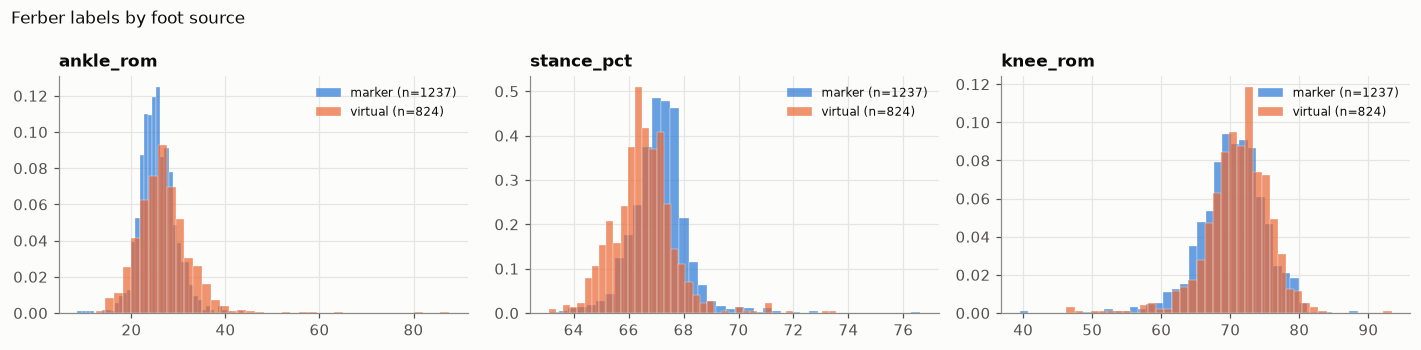

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for a, c in zip(axs, ["ankle_rom", "stance_pct", "knee_rom"]):
    for i, src in enumerate(["marker", "virtual"]):
        v = R.loc[R.keep & (R.toe_source == src), c]
        a.hist(v, bins=40, density=True, color=SERIES[i], alpha=0.7, label=f"{src} (n={len(v)})", edgecolor=SURFACE, linewidth=0.3)
    a.set_title(c); a.legend(fontsize=8)
fig.suptitle("Ferber labels by foot source", x=0.01, ha="left", fontsize=11); fig.tight_layout(); save(fig, "02_ferber_virtual_foot"); plt.show()

## Projection plane check
For treadmill trials the progression axis is the belt axis (snapped from mean heel→toe direction);
for overground it's PCA of the pelvis path. Out-of-plane (medio-lateral) motion is discarded —
the residual ML excursion of the pelvis tells us how much a side camera would miss.

/tmp/nix-shell.SqEfpj/ipykernel_42633/1319088454.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v, positions=[i], widths=0.5, vert=False, patch_artist=True,
/tmp/nix-shell.SqEfpj/ipykernel_42633/1319088454.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v, positions=[i], widths=0.5, vert=False, patch_artist=True,
/tmp/nix-shell.SqEfpj/ipykernel_42633/1319088454.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v, positions=[i], widths=0.5, vert=False, patch_artist=True,


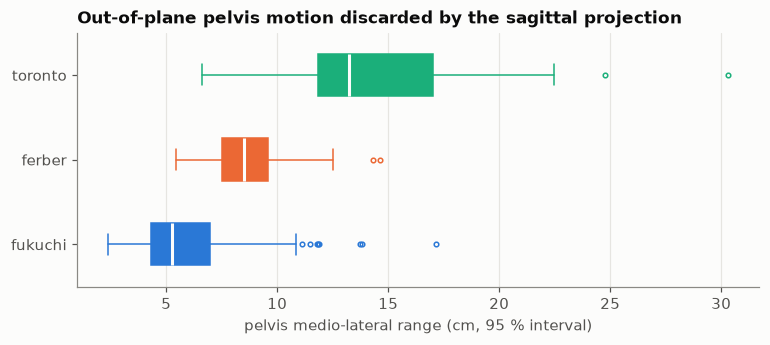

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
ferber,150.0,8.6,1.7,5.4,7.5,8.5,9.6,14.6
fukuchi,150.0,5.9,2.5,2.4,4.3,5.3,7.0,17.1
toronto,48.0,14.5,4.8,6.6,11.9,13.3,17.0,30.3


In [7]:
rows = []
for ds in DATASETS:
    for tr in trials(ds, True).trial.sample(min(150, len(trials(ds, True))), random_state=0):
        z = load_npz(ds, tr)
        up = z["up"]; f = z["fwd"]; m = np.cross(f, up)
        p = z["xyz"][:, J["pelvis"]].astype(float)
        ml = p @ m
        rows.append(dict(dataset=ds, trial=tr, ml_range_cm=100 * (np.percentile(ml, 97.5) - np.percentile(ml, 2.5))))
ML = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3))
for i, d in enumerate(DATASETS):
    v = ML.loc[ML.dataset == d, "ml_range_cm"]
    ax.boxplot(v, positions=[i], widths=0.5, vert=False, patch_artist=True,
               boxprops=dict(facecolor=COL[d], color=COL[d]), medianprops=dict(color=SURFACE, lw=2),
               whiskerprops=dict(color=COL[d]), capprops=dict(color=COL[d]), flierprops=dict(markeredgecolor=COL[d], markersize=3))
ax.set_yticks(range(3), DATASETS); ax.set_xlabel("pelvis medio-lateral range (cm, 95 % interval)")
ax.set_title("Out-of-plane pelvis motion discarded by the sagittal projection"); ax.grid(axis="y", visible=False)
save(fig, "02_ml_motion"); plt.show()
ML.groupby("dataset").ml_range_cm.describe().round(1)